In [1]:
# import os

# root = "/kaggle/input"

# for path, dirs, files in os.walk(root):
#     level = path.replace(root, "").count(os.sep)
#     indent = "    " * level
#     print(f"{indent}{os.path.basename(path)}/")

#     for file in sorted(files):
#         print(f"{indent}    {file}")

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

In [3]:
TRAIN_PATH = "/kaggle/input/datasets/vanshitasuryavanshi/btp-data/edaic_features/edaic_audio_features_train.csv"

DEV_PATH = "/kaggle/input/datasets/vanshitasuryavanshi/edaic-testdevdata/edaic_prepared/dev/edaic_audio_features_dev.csv"
TEST_PATH = "/kaggle/input/datasets/vanshitasuryavanshi/edaic-testdevdata/edaic_prepared/test/edaic_audio_features_test.csv"


train = pd.read_csv(TRAIN_PATH)
dev = pd.read_csv(DEV_PATH)
test = pd.read_csv(TEST_PATH)

print("Train:", train.shape)
print("Dev  :", dev.shape)
print("Test :", test.shape)

Train: (163, 196)
Dev  : (56, 196)
Test : (56, 196)


In [4]:
print("Train columns:")
print(train.columns.tolist())

print("\nFirst 5 rows:")
display(train.head())

Train columns:
['eg_Loudness_sma3_mean', 'eg_Loudness_sma3_std', 'eg_Loudness_sma3_median', 'eg_alphaRatio_sma3_mean', 'eg_alphaRatio_sma3_std', 'eg_alphaRatio_sma3_median', 'eg_hammarbergIndex_sma3_mean', 'eg_hammarbergIndex_sma3_std', 'eg_hammarbergIndex_sma3_median', 'eg_slope0-500_sma3_mean', 'eg_slope0-500_sma3_std', 'eg_slope0-500_sma3_median', 'eg_slope500-1500_sma3_mean', 'eg_slope500-1500_sma3_std', 'eg_slope500-1500_sma3_median', 'eg_spectralFlux_sma3_mean', 'eg_spectralFlux_sma3_std', 'eg_spectralFlux_sma3_median', 'eg_mfcc1_sma3_mean', 'eg_mfcc1_sma3_std', 'eg_mfcc1_sma3_median', 'eg_mfcc2_sma3_mean', 'eg_mfcc2_sma3_std', 'eg_mfcc2_sma3_median', 'eg_mfcc3_sma3_mean', 'eg_mfcc3_sma3_std', 'eg_mfcc3_sma3_median', 'eg_mfcc4_sma3_mean', 'eg_mfcc4_sma3_std', 'eg_mfcc4_sma3_median', 'eg_F0semitoneFrom27.5Hz_sma3nz_mean', 'eg_F0semitoneFrom27.5Hz_sma3nz_std', 'eg_F0semitoneFrom27.5Hz_sma3nz_median', 'eg_jitterLocal_sma3nz_mean', 'eg_jitterLocal_sma3nz_std', 'eg_jitterLocal_sma3nz_

,eg_Loudness_sma3_mean,eg_Loudness_sma3_std,eg_Loudness_sma3_median,eg_alphaRatio_sma3_mean,eg_alphaRatio_sma3_std,eg_alphaRatio_sma3_median,eg_hammarbergIndex_sma3_mean,eg_hammarbergIndex_sma3_std,eg_hammarbergIndex_sma3_median,eg_slope0-500_sma3_mean,...,Feature_Duration_sec,eGeMAPS_Frames,MFCC_Frames,Participant_ID,Gender,PHQ_Binary,PHQ_Score,PCL-C (PTSD),PTSD Severity,Split
0,0.094199,0.060997,0.065453,-15.264085,4.494209,-15.325215,25.444097,5.621548,25.799800,-0.021518,...,758.75,75876.0,75878.0,302.0,male,0,4,0,28.0,train
1,0.161740,0.134863,0.098868,-14.996058,5.863149,-15.433840,25.766606,7.041171,26.213365,-0.003281,...,985.25,98526.0,98528.0,303.0,female,0,0,0,17.0,train
2,0.123654,0.110712,0.074131,-15.657376,5.480203,-16.078585,25.482295,6.753119,26.058590,-0.009425,...,792.55,79256.0,79258.0,304.0,female,0,6,0,20.0,train
3,0.484929,0.373775,0.351518,-17.771436,5.520051,-18.386525,30.458521,6.591521,31.074590,-0.004643,...,1703.95,170396.0,170398.0,305.0,male,0,7,0,28.0,train
4,0.640995,0.490607,0.485032,-16.423802,6.951102,-17.241960,26.587544,8.991652,27.781150,0.011665,...,1238.78,123872.0,123878.0,307.0,female,0,4,0,23.0,train


In [5]:
# ==========================================
# AUDIO FEATURE SELECTION
# ==========================================

# eGeMAPS aggregated acoustic features
egemaps_cols = [
    c for c in train.columns
    if c.startswith("eg_") and not c.endswith("_Frames")
]

# MFCC aggregated acoustic features
mfcc_cols = [
    c for c in train.columns
    if c.startswith("mfcc_") and not c.endswith("_Frames")
]

# Combined audio features
audio_cols = sorted(egemaps_cols + mfcc_cols)

print("eGeMAPS features:", len(egemaps_cols))
print("MFCC features:", len(mfcc_cols))
print("Total audio features:", len(audio_cols))

eGeMAPS features: 69
MFCC features: 117
Total audio features: 186


In [6]:
# ==========================================
# VERIFY SAME FEATURES ACROSS SPLITS
# ==========================================

train_features = set(audio_cols)

dev_features = {
    c for c in dev.columns
    if c.startswith(("eg_", "mfcc_"))
    and not c.endswith("_Frames")
}

test_features = {
    c for c in test.columns
    if c.startswith(("eg_", "mfcc_"))
    and not c.endswith("_Frames")
}

print("Train - Dev:", train_features - dev_features)
print("Dev - Train:", dev_features - train_features)

print("Train - Test:", train_features - test_features)
print("Test - Train:", test_features - train_features)

Train - Dev: set()
Dev - Train: set()
Train - Test: set()
Test - Train: set()


In [7]:
X_train = train[audio_cols].copy()
X_dev = dev[audio_cols].copy()
X_test = test[audio_cols].copy()

print("X_train:", X_train.shape)
print("X_dev:", X_dev.shape)
print("X_test:", X_test.shape)

X_train: (163, 186)
X_dev: (56, 186)
X_test: (56, 186)


In [8]:
audio_cols = sorted(train_features)

X_train = train[audio_cols].copy()
X_dev = dev[audio_cols].copy()
X_test = test[audio_cols].copy()

In [9]:
metadata_cols = [
    "Feature_Duration_sec",
    "eGeMAPS_Frames",
    "MFCC_Frames",
    "Participant_ID",
    "Gender",
    "PHQ_Binary",
    "PHQ_Score",
    "PCL-C (PTSD)",
    "PTSD Severity",
    "Split"
]

print("Metadata accidentally included:")
print(set(metadata_cols) & set(audio_cols))

Metadata accidentally included:
set()


In [10]:
print(train.columns.tolist())
print(train["PHQ_Binary"].value_counts())
print()
print(dev["PHQ_Binary"].value_counts())
print()
print(test["PHQ_Binary"].value_counts())

['eg_Loudness_sma3_mean', 'eg_Loudness_sma3_std', 'eg_Loudness_sma3_median', 'eg_alphaRatio_sma3_mean', 'eg_alphaRatio_sma3_std', 'eg_alphaRatio_sma3_median', 'eg_hammarbergIndex_sma3_mean', 'eg_hammarbergIndex_sma3_std', 'eg_hammarbergIndex_sma3_median', 'eg_slope0-500_sma3_mean', 'eg_slope0-500_sma3_std', 'eg_slope0-500_sma3_median', 'eg_slope500-1500_sma3_mean', 'eg_slope500-1500_sma3_std', 'eg_slope500-1500_sma3_median', 'eg_spectralFlux_sma3_mean', 'eg_spectralFlux_sma3_std', 'eg_spectralFlux_sma3_median', 'eg_mfcc1_sma3_mean', 'eg_mfcc1_sma3_std', 'eg_mfcc1_sma3_median', 'eg_mfcc2_sma3_mean', 'eg_mfcc2_sma3_std', 'eg_mfcc2_sma3_median', 'eg_mfcc3_sma3_mean', 'eg_mfcc3_sma3_std', 'eg_mfcc3_sma3_median', 'eg_mfcc4_sma3_mean', 'eg_mfcc4_sma3_std', 'eg_mfcc4_sma3_median', 'eg_F0semitoneFrom27.5Hz_sma3nz_mean', 'eg_F0semitoneFrom27.5Hz_sma3nz_std', 'eg_F0semitoneFrom27.5Hz_sma3nz_median', 'eg_jitterLocal_sma3nz_mean', 'eg_jitterLocal_sma3nz_std', 'eg_jitterLocal_sma3nz_median', 'eg_sh

In [11]:
summary = pd.DataFrame({
    "Split": ["Train", "Dev", "Test"],
    "Samples": [len(train), len(dev), len(test)],
    "PHQ=0": [
        (train["PHQ_Binary"] == 0).sum(),
        (dev["PHQ_Binary"] == 0).sum(),
        (test["PHQ_Binary"] == 0).sum()
    ],
    "PHQ=1": [
        (train["PHQ_Binary"] == 1).sum(),
        (dev["PHQ_Binary"] == 1).sum(),
        (test["PHQ_Binary"] == 1).sum()
    ]
})

display(summary)

,Split,Samples,PHQ=0,PHQ=1
0,Train,163,126,37
1,Dev,56,44,12
2,Test,56,39,17


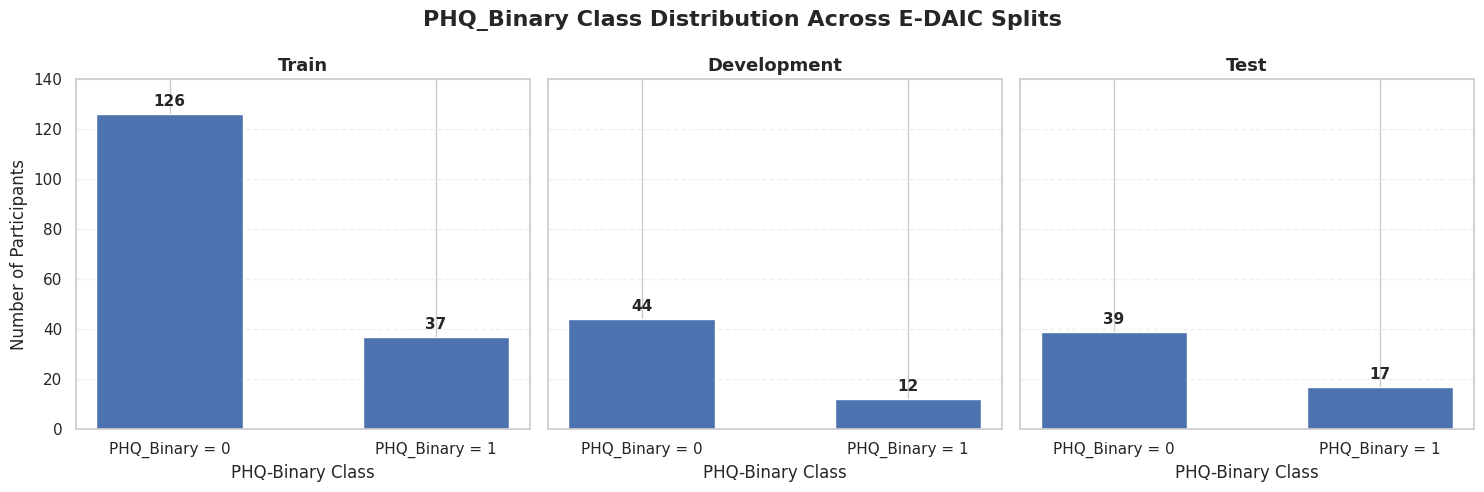

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Data from E-DAIC
splits = ['Train', 'Development', 'Test']

phq_0 = [126, 44, 39]
phq_1 = [37, 12, 17]

x = np.arange(len(splits))
width = 0.35

# Create three-panel figure
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

data = [
    ('Train', phq_0[0], phq_1[0]),
    ('Development', phq_0[1], phq_1[1]),
    ('Test', phq_0[2], phq_1[2])
]

for ax, (split, c0, c1) in zip(axes, data):
    bars = ax.bar(
        ['PHQ_Binary = 0', 'PHQ_Binary = 1'],
        [c0, c1],
        width=0.55
    )
    
    # Add count labels on top of bars
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 2,
            str(int(height)),
            ha='center',
            va='bottom',
            fontsize=11,
            fontweight='bold'
        )
    
    ax.set_title(split, fontsize=13, fontweight='bold')
    ax.set_xlabel('PHQ-Binary Class')
    ax.set_ylim(0, 140)
    ax.grid(axis='y', linestyle='--', alpha=0.3)

axes[0].set_ylabel('Number of Participants')

fig.suptitle(
    'PHQ_Binary Class Distribution Across E-DAIC Splits',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

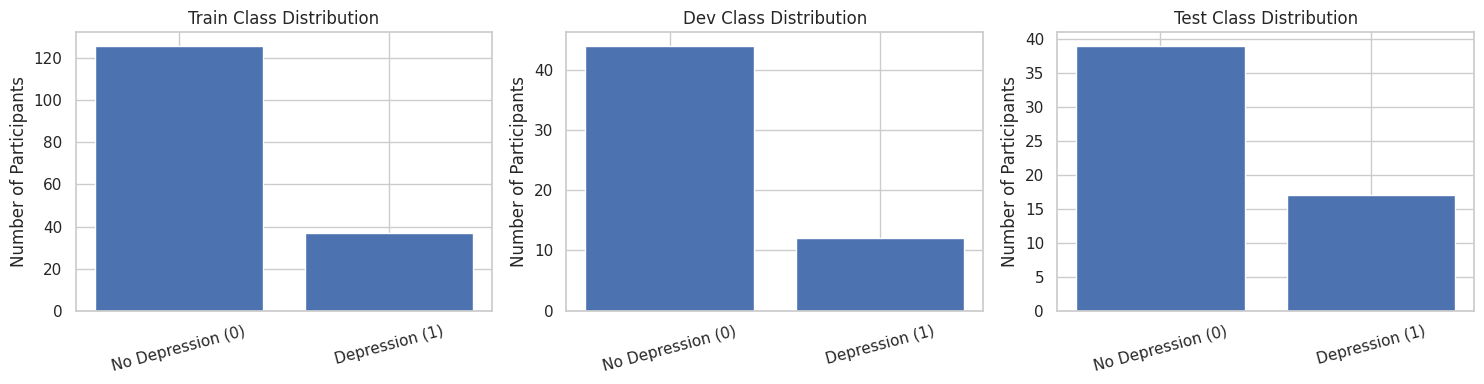

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

splits = {
    "Train": train,
    "Dev": dev,
    "Test": test
}

for ax, (name, df) in zip(axes, splits.items()):
    counts = df["PHQ_Binary"].value_counts().sort_index()

    ax.bar(["No Depression (0)", "Depression (1)"], counts.values)
    ax.set_title(f"{name} Class Distribution")
    ax.set_ylabel("Number of Participants")
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

In [14]:
missing = X_train.isna().sum()

missing_summary = pd.DataFrame({
    "Feature": missing.index,
    "Missing_Count": missing.values,
    "Missing_Percentage": 100 * missing.values / len(X_train)
})

missing_summary = (
    missing_summary
    .sort_values("Missing_Percentage", ascending=False)
)

display(missing_summary.head(10))

print(
    f"Total missing values: {X_train.isna().sum().sum():,}"
)

print(
    f"Features containing missing values: "
    f"{(X_train.isna().sum() > 0).sum()} / {X_train.shape[1]}"
)

,Feature,Missing_Count,Missing_Percentage
0,eg_F0semitoneFrom27.5Hz_sma3nz_mean,0,0.0
1,eg_F0semitoneFrom27.5Hz_sma3nz_median,0,0.0
2,eg_F0semitoneFrom27.5Hz_sma3nz_std,0,0.0
3,eg_F1amplitudeLogRelF0_sma3nz_mean,0,0.0
4,eg_F1amplitudeLogRelF0_sma3nz_median,0,0.0
5,eg_F1amplitudeLogRelF0_sma3nz_std,0,0.0
6,eg_F1bandwidth_sma3nz_mean,0,0.0
7,eg_F1bandwidth_sma3nz_median,0,0.0
8,eg_F1bandwidth_sma3nz_std,0,0.0
9,eg_F1frequency_sma3nz_mean,0,0.0


Total missing values: 0
Features containing missing values: 0 / 186


In [15]:
feature_stats = X_train.describe().T

feature_stats["missing"] = X_train.isna().sum()
feature_stats["missing_pct"] = (
    X_train.isna().mean() * 100
)

display(feature_stats)

os.makedirs("/kaggle/working/eda_outputs", exist_ok=True)

feature_stats.to_csv(
    "/kaggle/working/eda_outputs/feature_statistics.csv"
)

,count,mean,std,min,25%,50%,75%,max,missing,missing_pct
eg_F0semitoneFrom27.5Hz_sma3nz_mean,163.0,7.506803,3.396777,1.403222,4.698248,7.007406e+00,9.542351,15.737482,0,0.0
eg_F0semitoneFrom27.5Hz_sma3nz_median,163.0,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0,0.0
eg_F0semitoneFrom27.5Hz_sma3nz_std,163.0,12.064686,3.034505,5.845080,9.671907,1.191673e+01,14.820830,17.936218,0,0.0
eg_F1amplitudeLogRelF0_sma3nz_mean,163.0,-22.072208,4.309878,-36.525461,-24.985002,-2.207813e+01,-18.685993,-11.062840,0,0.0
eg_F1amplitudeLogRelF0_sma3nz_median,163.0,-6.217048,3.445467,-17.756130,-8.410859,-5.697914e+00,-3.932812,1.854538,0,0.0
...,...,...,...,...,...,...,...,...,...,...
mfcc_pcm_fftMag_mfcc_de_de[8]_median,163.0,-0.000491,0.006472,-0.020336,-0.004113,-2.638102e-04,0.004109,0.017224,0,0.0
mfcc_pcm_fftMag_mfcc_de_de[8]_std,163.0,1.343335,0.095413,1.117146,1.276918,1.336115e+00,1.414630,1.655346,0,0.0
mfcc_pcm_fftMag_mfcc_de_de[9]_mean,163.0,0.000002,0.000034,-0.000089,-0.000017,8.689103e-07,0.000025,0.000119,0,0.0
mfcc_pcm_fftMag_mfcc_de_de[9]_median,163.0,0.003569,0.004953,-0.010289,0.000642,3.345257e-03,0.006712,0.021071,0,0.0


In [16]:
print("eGeMAPS features:", len(egemaps_cols))
print("MFCC features:", len(mfcc_cols))

egemaps_means = train.groupby("PHQ_Binary")[egemaps_cols].mean().T
mfcc_means = train.groupby("PHQ_Binary")[mfcc_cols].mean().T

display(egemaps_means.head())
display(mfcc_means.head())

eGeMAPS features: 69
MFCC features: 117


PHQ_Binary,0,1
eg_Loudness_sma3_mean,0.099458,0.089494
eg_Loudness_sma3_std,0.110359,0.103620
eg_Loudness_sma3_median,0.050452,0.040417
eg_alphaRatio_sma3_mean,-16.223585,-16.113940
eg_alphaRatio_sma3_std,7.519254,7.248735


PHQ_Binary,0,1
mfcc_pcm_fftMag_mfcc[0]_mean,-4.550565,-5.173120
mfcc_pcm_fftMag_mfcc[0]_std,13.589051,12.792897
mfcc_pcm_fftMag_mfcc[0]_median,-7.274023,-8.397224
mfcc_pcm_fftMag_mfcc[1]_mean,-2.734608,-2.740932
mfcc_pcm_fftMag_mfcc[1]_std,12.172666,11.398598


In [17]:
def effect_size(df, cols):
    rows = []

    for col in cols:
        x0 = df.loc[df["PHQ_Binary"] == 0, col].dropna()
        x1 = df.loc[df["PHQ_Binary"] == 1, col].dropna()

        if len(x0) < 2 or len(x1) < 2:
            continue

        m0 = x0.mean()
        m1 = x1.mean()

        s0 = x0.std()
        s1 = x1.std()

        pooled = np.sqrt((s0**2 + s1**2) / 2)

        if pooled == 0:
            d = 0
        else:
            d = (m1 - m0) / pooled

        rows.append({
            "Feature": col,
            "Class0_Mean": m0,
            "Class1_Mean": m1,
            "Effect_Size": d,
            "Abs_Effect_Size": abs(d)
        })

    return pd.DataFrame(rows).sort_values(
        "Abs_Effect_Size",
        ascending=False
    )

In [18]:
egemaps_effect = effect_size(train, egemaps_cols)
mfcc_effect = effect_size(train, mfcc_cols)

display(egemaps_effect.head(15))
display(mfcc_effect.head(15))

,Feature,Class0_Mean,Class1_Mean,Effect_Size,Abs_Effect_Size
26,eg_mfcc3_sma3_median,8.213065,7.278106,-0.517467,0.517467
37,eg_shimmerLocaldB_sma3nz_std,0.716741,0.662834,-0.475015,0.475015
36,eg_shimmerLocaldB_sma3nz_mean,0.271138,0.233802,-0.431561,0.431561
56,eg_F1amplitudeLogRelF0_sma3nz_median,-5.878726,-7.369169,-0.406241,0.406241
19,eg_mfcc1_sma3_std,12.918787,12.188608,-0.394594,0.394594
25,eg_mfcc3_sma3_std,11.922660,11.297326,-0.360855,0.360855
22,eg_mfcc2_sma3_std,11.055114,10.377354,-0.348475,0.348475
13,eg_slope500-1500_sma3_std,0.016041,0.015232,-0.340003,0.340003
4,eg_alphaRatio_sma3_std,7.519254,7.248735,-0.315356,0.315356
50,eg_F1frequency_sma3nz_median,589.019740,601.719481,0.314906,0.314906


,Feature,Class0_Mean,Class1_Mean,Effect_Size,Abs_Effect_Size
95,mfcc_pcm_fftMag_mfcc_de_de[5]_median,-0.012411,-0.008514,0.550687,0.550687
8,mfcc_pcm_fftMag_mfcc[2]_median,-0.936520,-1.846540,-0.481818,0.481818
34,mfcc_pcm_fftMag_mfcc[11]_std,10.865052,10.238111,-0.480652,0.480652
14,mfcc_pcm_fftMag_mfcc[4]_median,-1.258337,0.283980,0.478988,0.478988
73,mfcc_pcm_fftMag_mfcc_de[11]_std,2.701976,2.616050,-0.466868,0.466868
80,mfcc_pcm_fftMag_mfcc_de_de[0]_median,-0.012931,-0.010195,0.454072,0.454072
12,mfcc_pcm_fftMag_mfcc[4]_mean,-3.903756,-2.128204,0.446162,0.446162
103,mfcc_pcm_fftMag_mfcc_de_de[8]_std,1.352335,1.312687,-0.438606,0.438606
30,mfcc_pcm_fftMag_mfcc[10]_mean,0.866748,-0.363173,-0.432071,0.432071
64,mfcc_pcm_fftMag_mfcc_de[8]_std,3.149644,3.045569,-0.431380,0.431380


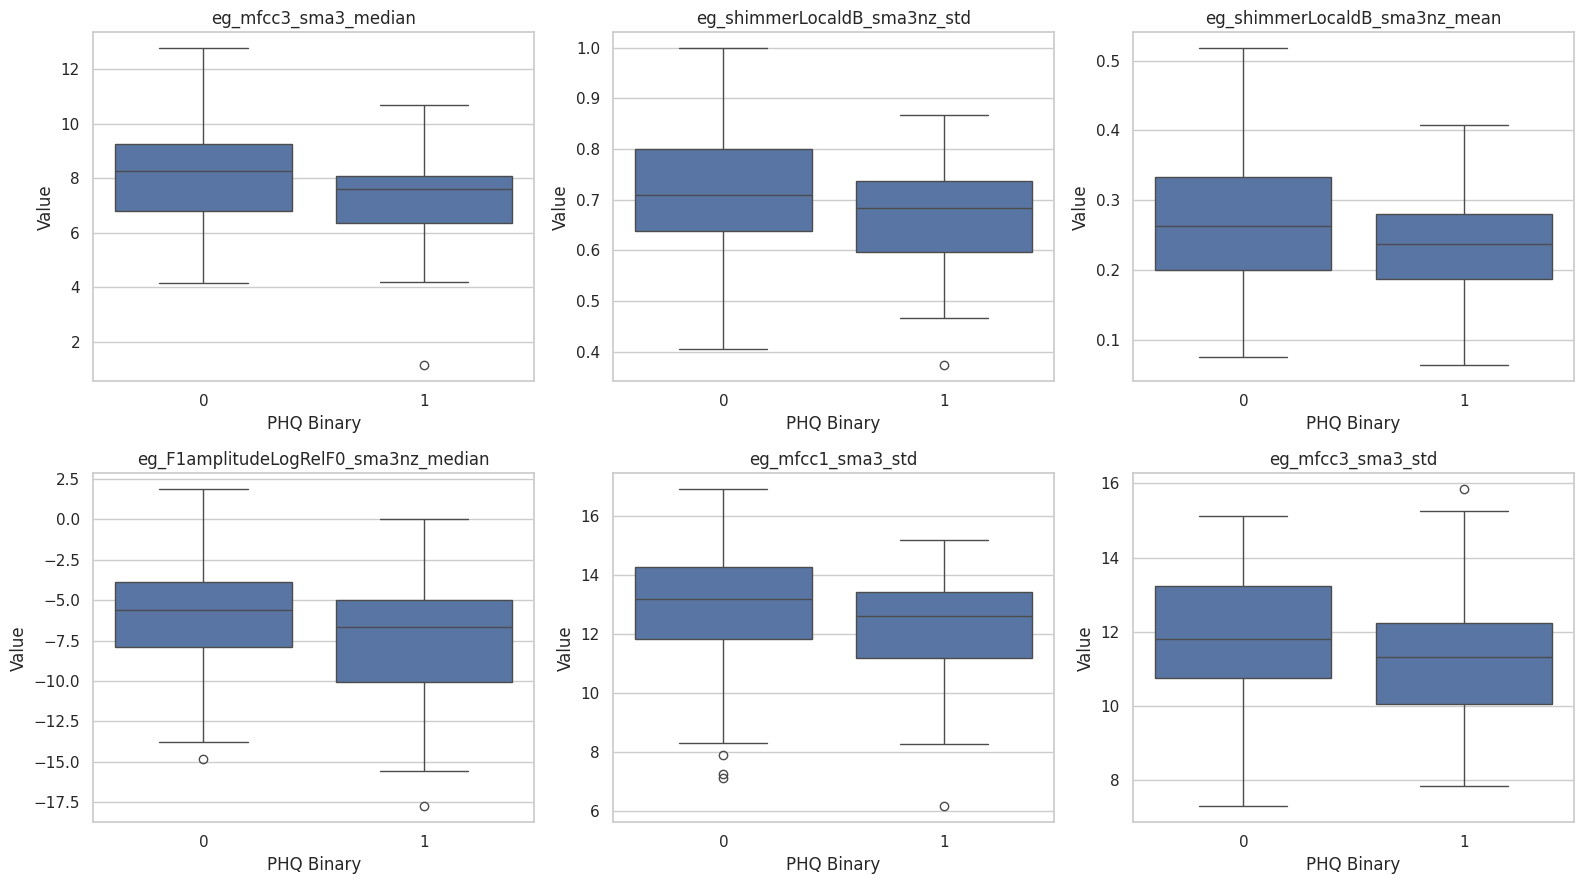

In [19]:
top_egemaps = egemaps_effect.head(6)["Feature"].tolist()

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, col in zip(axes, top_egemaps):
    sns.boxplot(
        data=train,
        x="PHQ_Binary",
        y=col,
        ax=ax
    )

    ax.set_title(col)
    ax.set_xlabel("PHQ Binary")
    ax.set_ylabel("Value")

plt.tight_layout()
plt.show()

In [20]:
corr = X_train.corr()

upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

corr_pairs = (
    upper.stack()
    .reset_index()
)

corr_pairs.columns = ["Feature_1", "Feature_2", "Correlation"]

corr_pairs["Abs_Correlation"] = corr_pairs["Correlation"].abs()

corr_pairs = corr_pairs.sort_values(
    "Abs_Correlation",
    ascending=False
)

display(corr_pairs.head(20))

,Feature_1,Feature_2,Correlation,Abs_Correlation
6541,eg_mfcc1_sma3_median,mfcc_pcm_fftMag_mfcc[0]_median,0.998195,0.998195
6402,eg_mfcc1_sma3_mean,mfcc_pcm_fftMag_mfcc[0]_mean,0.995339,0.995339
14663,mfcc_pcm_fftMag_mfcc_de[4]_std,mfcc_pcm_fftMag_mfcc_de_de[4]_std,0.994865,0.994865
7626,eg_mfcc4_sma3_mean,mfcc_pcm_fftMag_mfcc[3]_mean,0.993734,0.993734
7230,eg_mfcc3_sma3_mean,mfcc_pcm_fftMag_mfcc[2]_mean,0.993633,0.993633
14822,mfcc_pcm_fftMag_mfcc_de[5]_std,mfcc_pcm_fftMag_mfcc_de_de[5]_std,0.993152,0.993152
14495,mfcc_pcm_fftMag_mfcc_de[3]_std,mfcc_pcm_fftMag_mfcc_de_de[3]_std,0.992823,0.992823
7096,eg_mfcc2_sma3_std,mfcc_pcm_fftMag_mfcc[1]_std,0.992530,0.992530
13937,mfcc_pcm_fftMag_mfcc_de[12]_std,mfcc_pcm_fftMag_mfcc_de_de[12]_std,0.992520,0.992520
6825,eg_mfcc2_sma3_mean,mfcc_pcm_fftMag_mfcc[1]_mean,0.992331,0.992331


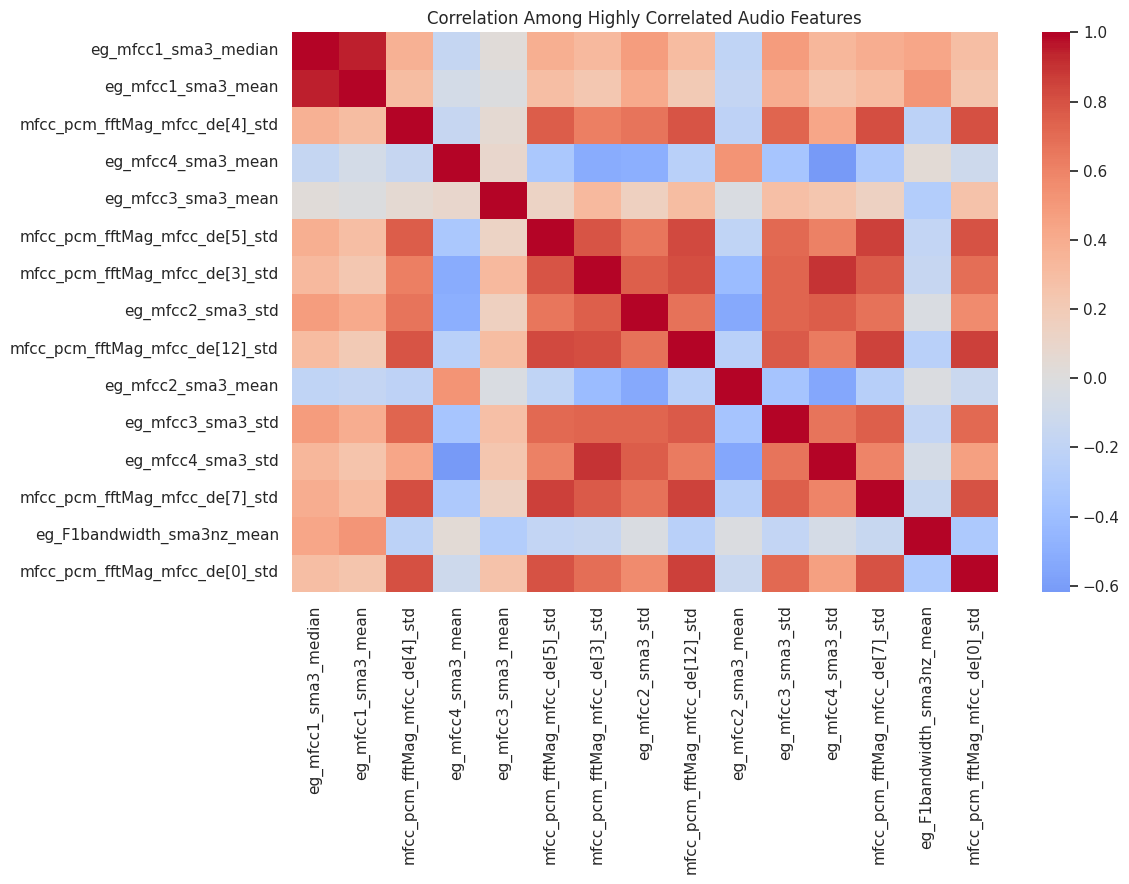

In [21]:
top_corr_features = corr_pairs.head(15)["Feature_1"].tolist()

plt.figure(figsize=(12, 9))

sns.heatmap(
    X_train[top_corr_features].corr(),
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Among Highly Correlated Audio Features")
plt.tight_layout()
plt.show()

Explained variance:
[0.28624882 0.09501769]
Total: 0.38126650838899623


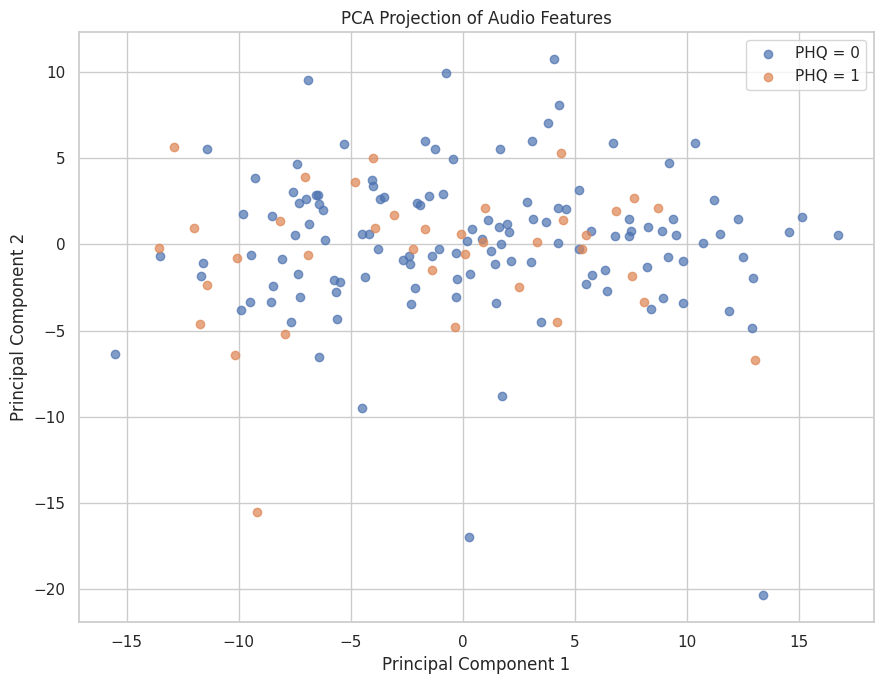

In [22]:
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train_imp = imputer.fit_transform(X_train)
X_train_scaled = scaler.fit_transform(X_train_imp)

pca = PCA(n_components=2, random_state=42)

X_train_pca = pca.fit_transform(X_train_scaled)

print("Explained variance:")
print(pca.explained_variance_ratio_)
print("Total:", pca.explained_variance_ratio_.sum())

plt.figure(figsize=(9, 7))

plt.scatter(
    X_train_pca[train["PHQ_Binary"] == 0, 0],
    X_train_pca[train["PHQ_Binary"] == 0, 1],
    label="PHQ = 0",
    alpha=0.7
)

plt.scatter(
    X_train_pca[train["PHQ_Binary"] == 1, 0],
    X_train_pca[train["PHQ_Binary"] == 1, 1],
    label="PHQ = 1",
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Projection of Audio Features")
plt.legend()

plt.tight_layout()
plt.show()

In [23]:
y_train = train["PHQ_Binary"].astype(int)
y_dev = dev["PHQ_Binary"].astype(int)
y_test = test["PHQ_Binary"].astype(int)

In [24]:
def evaluate_model(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(
            y_true, y_prob
        ),
        "PR_AUC": average_precision_score(
            y_true, y_prob
        )
    }

1. LOGISTIC REGRESSION

In [25]:
logistic = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    (
        "model",
        LogisticRegression(
            class_weight="balanced",
            max_iter=5000,
            random_state=42
        )
    )
])

logistic.fit(X_train, y_train)

pred_dev = logistic.predict(X_dev)
prob_dev = logistic.predict_proba(X_dev)[:, 1]

In [26]:
results = []

results.append(
    evaluate_model(
        "Logistic Regression",
        y_dev,
        pred_dev,
        prob_dev
    )
)

display(pd.DataFrame(results))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.696429,0.333333,0.416667,0.37037,0.689394,0.494034


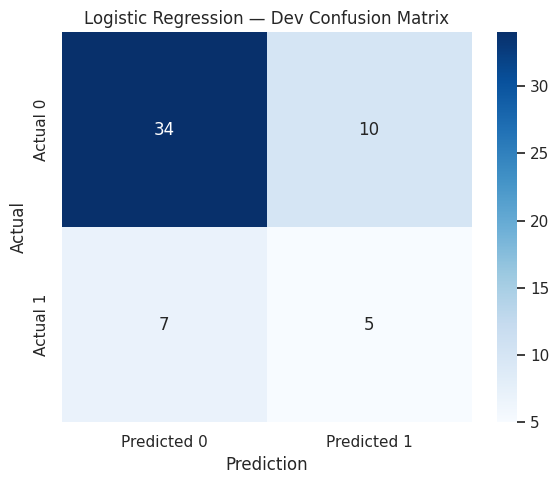

              precision    recall  f1-score   support

     PHQ = 0       0.83      0.77      0.80        44
     PHQ = 1       0.33      0.42      0.37        12

    accuracy                           0.70        56
   macro avg       0.58      0.59      0.59        56
weighted avg       0.72      0.70      0.71        56



In [27]:
cm = confusion_matrix(y_dev, pred_dev)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"]
)

plt.title("Logistic Regression — Dev Confusion Matrix")
plt.xlabel("Prediction")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

print(
    classification_report(
        y_dev,
        pred_dev,
        target_names=["PHQ = 0", "PHQ = 1"],
        zero_division=0
    )
)

2 RANDOM FOREST

In [28]:
rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    (
        "model",
        RandomForestClassifier(
            n_estimators=500,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    )
])

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_dev)
rf_prob = rf.predict_proba(X_dev)[:, 1]

results.append(
    evaluate_model(
        "Random Forest",
        y_dev,
        rf_pred,
        rf_prob
    )
)

3. SVM

In [29]:
svm = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    (
        "model",
        SVC(
            kernel="rbf",
            C=1.0,
            probability=True,
            class_weight="balanced",
            random_state=42
        )
    )
])

svm.fit(X_train, y_train)

svm_pred = svm.predict(X_dev)
svm_prob = svm.predict_proba(X_dev)[:, 1]

results.append(
    evaluate_model(
        "SVM",
        y_dev,
        svm_pred,
        svm_prob
    )
)

In [30]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "F1",
    ascending=False
)

display(results_df)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.696429,0.333333,0.416667,0.370370,0.689394,0.494034
2,SVM,0.642857,0.277778,0.416667,0.333333,0.704545,0.435171
1,Random Forest,0.785714,0.000000,0.000000,0.000000,0.757576,0.413775


In [31]:
feature_sets = {
    "eGeMAPS": egemaps_cols,
    "MFCC": mfcc_cols,
    "Combined": audio_cols
}

In [32]:
comparison = []

for name, cols in feature_sets.items():

    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        (
            "model",
            LogisticRegression(
                class_weight="balanced",
                max_iter=5000,
                random_state=42
            )
        )
    ])

    model.fit(
        train[cols],
        y_train
    )

    pred = model.predict(dev[cols])
    prob = model.predict_proba(dev[cols])[:, 1]

    row = evaluate_model(
        name,
        y_dev,
        pred,
        prob
    )

    comparison.append(row)

comparison_df = pd.DataFrame(comparison)

display(comparison_df)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,eGeMAPS,0.625000,0.235294,0.333333,0.275862,0.467803,0.254095
1,MFCC,0.732143,0.384615,0.416667,0.400000,0.679924,0.473075
2,Combined,0.696429,0.333333,0.416667,0.370370,0.689394,0.494034


In [33]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=5000,
            random_state=42
        ))
    ]),

    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            C=1.0,
            probability=True,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=500,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

In [34]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "PR-AUC": scores["test_pr_auc"].mean(),
        "F1_STD": scores["test_f1"].std(),
        "ROC_AUC_STD": scores["test_roc_auc"].std(),
        "PR_AUC_STD": scores["test_pr_auc"].std()
    })

cv_df = pd.DataFrame(cv_results)

display(
    cv_df.sort_values("PR-AUC", ascending=False)
)

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.p

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,F1_STD,ROC_AUC_STD,PR_AUC_STD
0,Logistic Regression,0.644697,0.215714,0.214286,0.213492,0.605989,0.325853,0.052549,0.077557,0.058068
2,Random Forest,0.773106,0.000000,0.000000,0.000000,0.525027,0.308244,0.000000,0.106826,0.096965
1,SVM,0.619697,0.183434,0.214286,0.193927,0.519615,0.287105,0.135354,0.105579,0.091304


In [35]:
from sklearn.model_selection import cross_val_predict

oof_results = {}

for name, model in models.items():

    prob = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    oof_results[name] = prob

In [36]:
thresholds = np.arange(0.10, 0.91, 0.05)

threshold_rows = []

for name, prob in oof_results.items():

    for t in thresholds:

        pred = (prob >= t).astype(int)

        threshold_rows.append({
            "Model": name,
            "Threshold": t,
            "Precision": precision_score(
                y_train, pred, zero_division=0
            ),
            "Recall": recall_score(
                y_train, pred, zero_division=0
            ),
            "F1": f1_score(
                y_train, pred, zero_division=0
            ),
            "Accuracy": accuracy_score(
                y_train, pred
            )
        })

threshold_df = pd.DataFrame(threshold_rows)

display(threshold_df)

,Model,Threshold,Precision,Recall,F1,Accuracy
0,Logistic Regression,0.10,0.265823,0.567568,0.362069,0.546012
1,Logistic Regression,0.15,0.275362,0.513514,0.358491,0.582822
2,Logistic Regression,0.20,0.287879,0.513514,0.368932,0.601227
3,Logistic Regression,0.25,0.278689,0.459459,0.346939,0.607362
4,Logistic Regression,0.30,0.288136,0.459459,0.354167,0.619632
5,Logistic Regression,0.35,0.296296,0.432432,0.351648,0.638037
6,Logistic Regression,0.40,0.288462,0.405405,0.337079,0.638037
7,Logistic Regression,0.45,0.255814,0.297297,0.275000,0.644172
8,Logistic Regression,0.50,0.216216,0.216216,0.216216,0.644172
9,Logistic Regression,0.55,0.228571,0.216216,0.222222,0.656442


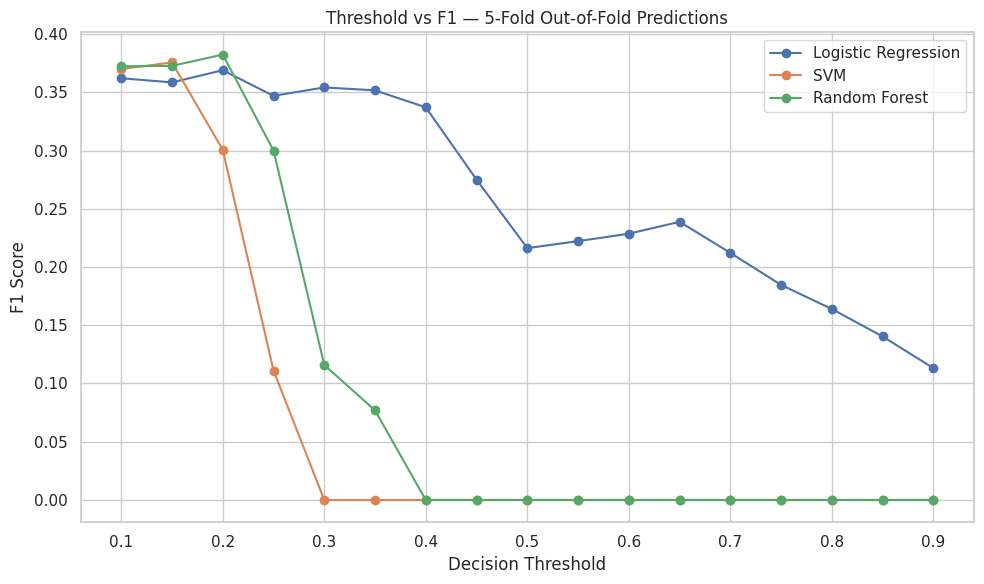

In [37]:
plt.figure(figsize=(10, 6))

for name in models:
    d = threshold_df[threshold_df["Model"] == name]

    plt.plot(
        d["Threshold"],
        d["F1"],
        marker="o",
        label=name
    )

plt.xlabel("Decision Threshold")
plt.ylabel("F1 Score")
plt.title("Threshold vs F1 — 5-Fold Out-of-Fold Predictions")
plt.legend()
plt.tight_layout()
plt.show()

In [38]:
best_thresholds = {
    "Logistic Regression": 0.20,
    "SVM": 0.15,
    "Random Forest": 0.20
}

In [39]:
dev_threshold_results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    prob = model.predict_proba(X_dev)[:, 1]

    t = best_thresholds[name]

    pred = (prob >= t).astype(int)

    dev_threshold_results.append({
        "Model": name,
        "Threshold": t,
        "Accuracy": accuracy_score(y_dev, pred),
        "Precision": precision_score(
            y_dev, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_dev, pred, zero_division=0
        ),
        "F1": f1_score(
            y_dev, pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_dev, prob
        ),
        "PR-AUC": average_precision_score(
            y_dev, prob
        )
    })

dev_threshold_df = pd.DataFrame(dev_threshold_results)

display(dev_threshold_df)

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.20,0.750000,0.444444,0.666667,0.533333,0.689394,0.494034
1,SVM,0.15,0.214286,0.214286,1.000000,0.352941,0.704545,0.435171
2,Random Forest,0.20,0.428571,0.261905,0.916667,0.407407,0.757576,0.413775


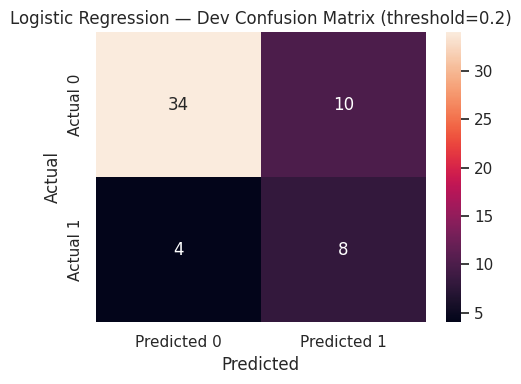

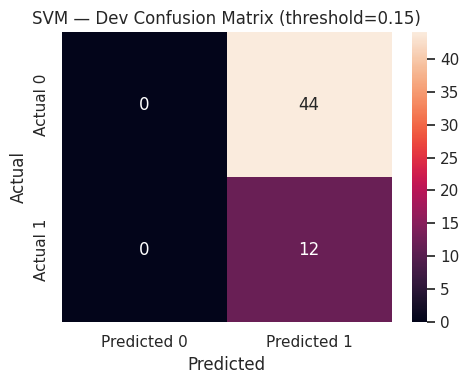

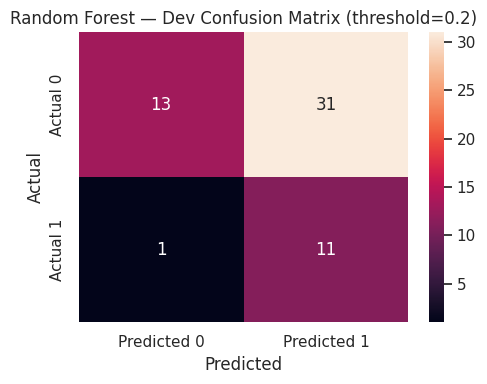

In [40]:
for name, model in models.items():

    model.fit(X_train, y_train)

    prob = model.predict_proba(X_dev)[:, 1]

    t = best_thresholds[name]
    pred = (prob >= t).astype(int)

    cm = confusion_matrix(y_dev, pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=["Predicted 0", "Predicted 1"],
        yticklabels=["Actual 0", "Actual 1"]
    )

    plt.title(f"{name} — Dev Confusion Matrix (threshold={t})")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.tight_layout()
    plt.show()

In [41]:
from sklearn.model_selection import cross_val_predict

feature_sets = {
    "eGeMAPS": egemaps_cols,
    "MFCC": mfcc_cols,
    "Combined": audio_cols
}

feature_set_models = {}
feature_set_oof = {}

for feature_name, cols in feature_sets.items():

    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=5000,
            random_state=42
        ))
    ])

    feature_set_models[feature_name] = model

    prob = cross_val_predict(
        model,
        train[cols],
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    feature_set_oof[feature_name] = prob

In [42]:
feature_thresholds = {}

for name, prob in feature_set_oof.items():

    best_f1 = -1
    best_t = 0.5

    for t in np.arange(0.10, 0.91, 0.01):

        pred = (prob >= t).astype(int)

        f1 = f1_score(
            y_train,
            pred,
            zero_division=0
        )

        if f1 > best_f1:
            best_f1 = f1
            best_t = t

    feature_thresholds[name] = best_t

print(feature_thresholds)

{'eGeMAPS': np.float64(0.23999999999999994), 'MFCC': np.float64(0.13), 'Combined': np.float64(0.19999999999999996)}


In [43]:
feature_set_results = []

for name, cols in feature_sets.items():

    model = feature_set_models[name]

    model.fit(
        train[cols],
        y_train
    )

    prob = model.predict_proba(
        dev[cols]
    )[:, 1]

    t = feature_thresholds[name]

    pred = (prob >= t).astype(int)

    feature_set_results.append({
        "Feature Set": name,
        "Threshold": t,
        "Accuracy": accuracy_score(y_dev, pred),
        "Precision": precision_score(
            y_dev, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_dev, pred, zero_division=0
        ),
        "F1": f1_score(
            y_dev, pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_dev, prob),
        "PR-AUC": average_precision_score(y_dev, prob)
    })

feature_set_results_df = pd.DataFrame(
    feature_set_results
)

display(feature_set_results_df)

,Feature Set,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,eGeMAPS,0.24,0.303571,0.170732,0.583333,0.264151,0.467803,0.254095
1,MFCC,0.13,0.553571,0.275862,0.666667,0.390244,0.679924,0.473075
2,Combined,0.20,0.750000,0.444444,0.666667,0.533333,0.689394,0.494034
